In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from statsmodels.stats.diagnostic import het_arch
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from arch import arch_model

In [38]:
volatility = pd.read_csv('TCS_sales.xls')
volatility.head()

,date,1. open,2. high,3. low,4. close,5. volume
0,2025-03-31,549.83,560.7112,546.87,559.39,95328213.0
1,2025-03-28,565.53,566.2675,555.07,555.66,71662653.0
2,2025-03-27,567.18,570.9000,564.94,567.08,42164248.0
3,2025-03-26,575.19,576.3300,567.19,568.59,52228898.0
4,2025-03-25,575.30,576.4100,573.69,575.46,38355735.0


In [39]:
volatility['date'] = pd.to_datetime(volatility['date'])
volatility_data = volatility.set_index('date')

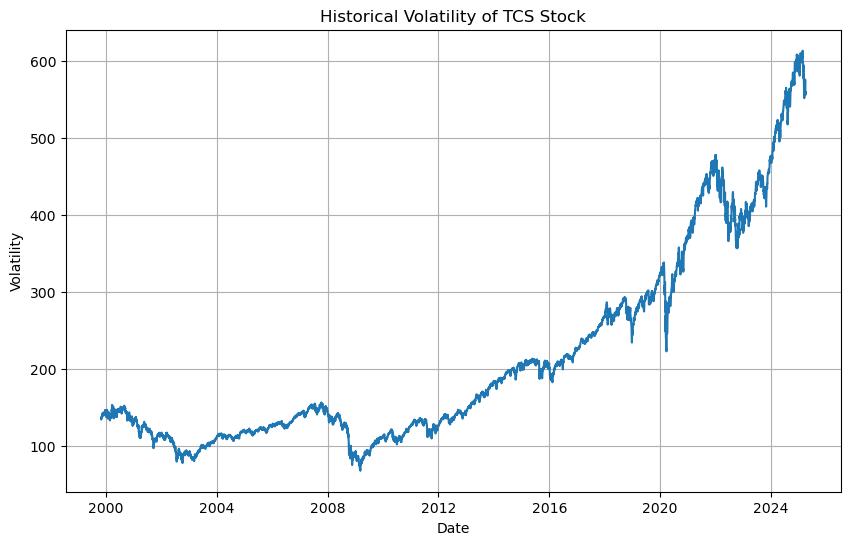

In [40]:
plt.figure(figsize=(10, 6))
plt.plot(volatility_data.index, volatility_data['4. close'])
plt.xlabel('Date')
plt.ylabel('Volatility')
plt.title('Historical Volatility of TCS Stock')
plt.grid(True)

plt.show()

In [41]:
returns = np.log(volatility_data['4. close']).diff().dropna()

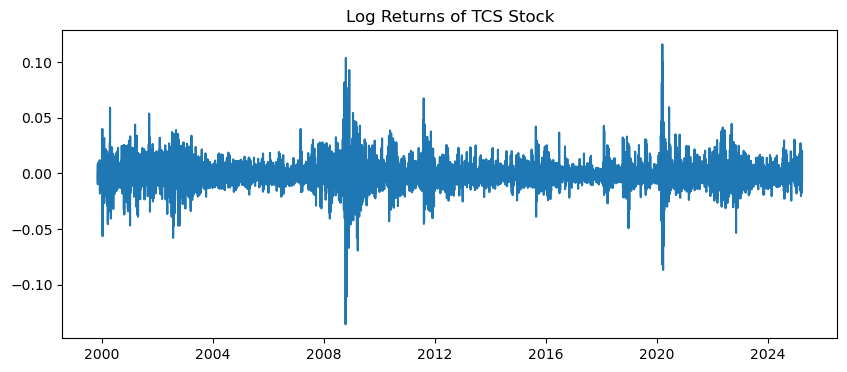

In [42]:
plt.figure(figsize=(10, 4))
plt.plot(returns)
plt.title('Log Returns of TCS Stock')
plt.show()

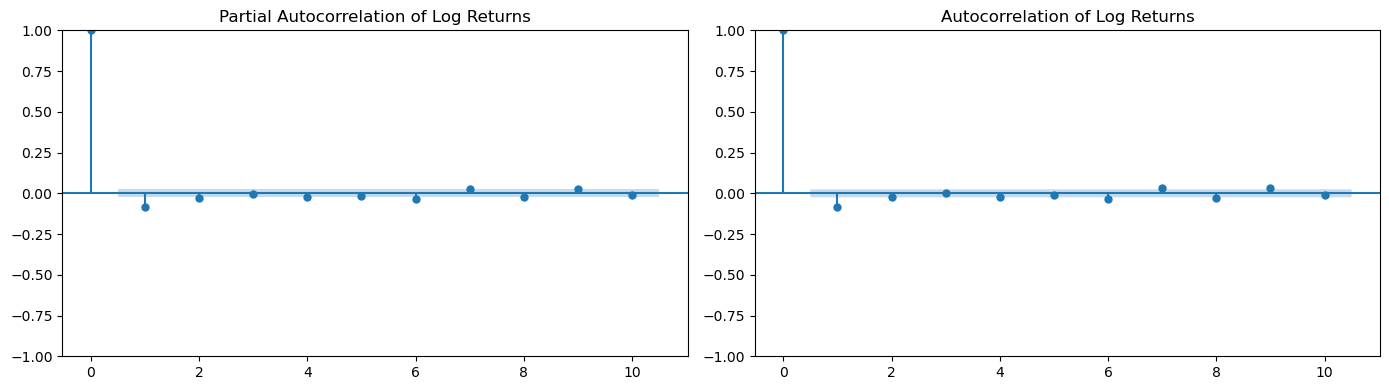

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_pacf(returns, lags=10, ax=axes[0])
axes[0].set_title('Partial Autocorrelation of Log Returns')

plot_acf(returns, lags=10, ax=axes[1])
axes[1].set_title('Autocorrelation of Log Returns')

plt.tight_layout()
plt.show()

In [44]:
from statsmodels.tsa.arima.model import ARIMA
mean_model = ARIMA(returns, order=(0, 0, 0)).fit()
residuals = mean_model.resid

c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it is not monotonic and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it is not monotonic and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\ProgramData\anaconda3\Lib\site-

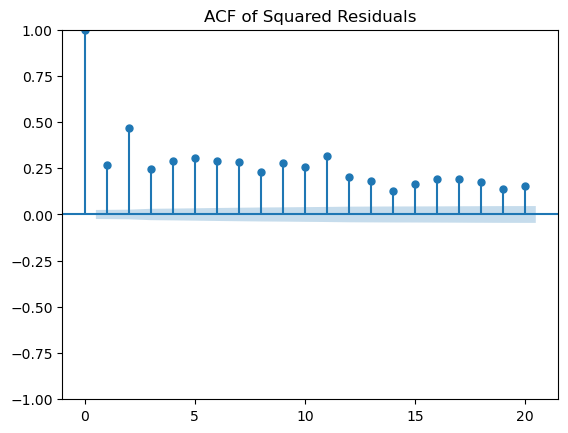

In [45]:
plot_acf(residuals**2, lags=20)
plt.title('ACF of Squared Residuals')
plt.show()

In [46]:
arch_test = het_arch(residuals)
print('LM Statistic:', arch_test[0])
print('p-value:', arch_test[1])

LM Statistic: 1850.553392980837
p-value: 0.0


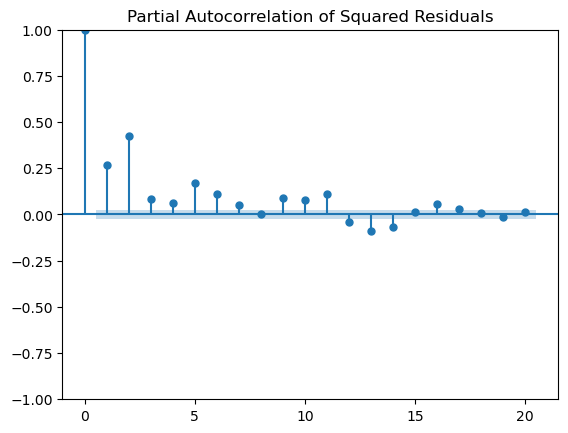

In [47]:
plot_pacf(residuals**2, lags=20)
plt.title('Partial Autocorrelation of Squared Residuals')
plt.show()

In [48]:
# Fit GARCH(1,1) model
garch = arch_model(returns, vol='Garch', p=1, q=1)
garch_result = garch.fit(disp='off')
print(garch_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:               4. close   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                20582.8
Distribution:                  Normal   AIC:                          -41157.6
Method:            Maximum Likelihood   BIC:                          -41130.6
                                        No. Observations:                 6391
Date:                Tue, Oct 06 2026   Df Residuals:                     6390
Time:                        13:03:09   Df Model:                            1
                                   Mean Model                                  
                  coef    std err          t      P>|t|        95.0% Conf. Int.
-------------------------------------------------------------------------------
mu         -2.0970e-04  8.590e-06    -24.412 1.28

C:\Users\tejas\AppData\Roaming\Python\Python313\site-packages\arch\univariate\base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.000149. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


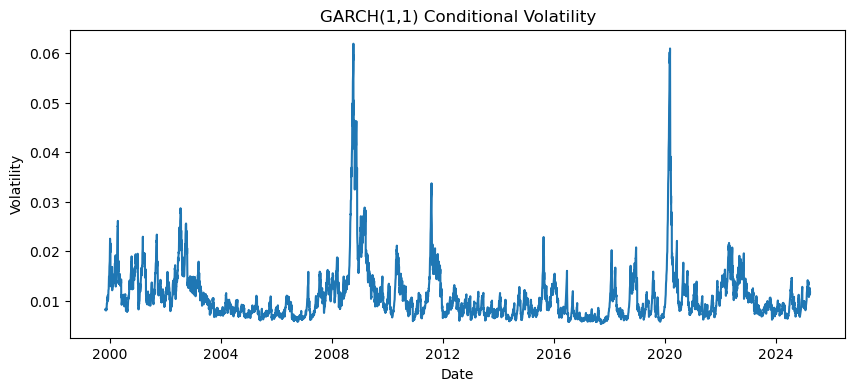

In [49]:
# Plot conditional volatility
plt.figure(figsize=(10, 4))
plt.plot(garch_result.conditional_volatility)
plt.title('GARCH(1,1) Conditional Volatility')
plt.xlabel('Date')
plt.ylabel('Volatility')
plt.show()